## -------------------------------------------------------------------------------------------------------------------

# PROYECTO DEL CEIEC - Network Traffic Classification, en colaboración con Foqum
# Descripción del notebook: entrenamiento de un modelo LSTM de clasificación, con un semiflujo como dato de entrada, y como salida el tipo de tráfico (clase) a la que pertenece
# Becario responsable del proyecto: Carlos Arranz Luque
# Directora de la investigación: Ana María Maitín López
# Fecha: curso académico 2022-2023

## -------------------------------------------------------------------------------------------------------------------

## Importación de librerías y módulos

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import normalize
import configparser

## Módulos/scripts propios
from src import *

## Este código recarga los módulos/librerías antes de cada ejecución parcial del código, de tal forma
## que podemos cambiar una función en mitad de la ejecución y dichos cambios serán efectivos sin necesidad
## de recargar el kernel. Esto es útil cuando aún se está en fase de desarrollo y hay que verificar si las
## funciones tienen el comportamiento deseado
%load_ext autoreload
%autoreload 2

2023-06-22 13:08:50.087671: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## -------------------------------------------------------------------------------------------------------------------

## Opciones de ejecución e hiperparámetros

In [2]:
## Leemos el archivo "config_entrenamiento.cfg" donde están las opciones de ejecución e hiperparámetros del entrenamiento
config = configparser.RawConfigParser()
config.read('config/config_entrenamiento_LSTM.cfg')

## Optenemos los diccionarios con los distintos parámetros de cada una de las categorías
opcionesEjecucion_dict = dict(config.items('OpcionesEjecucion'))
hiperparametros_dict = dict(config.items('Hiperparametros'))
rutasArchivos_dict = dict(config.items('RutasArchivos'))

In [3]:
### ----------------------------------------------------------------------------------------------
### ------------------------------ Opciones de ejecución -----------------------------------------
### ----------------------------------------------------------------------------------------------

# Si está a True, se cargan los pesos que se hayan guardado de un entrenamiento previo que usara el mismo 
# archivo de semiflujos, que se identifica con el "hashSemiflujos" (HS), y modelo, que se 
# identifica con el "hashModelo" (HM), que las opciones actuales.
# (Junto con los pesos se cargan datos adicionales, como el tiempo que tardó el entrenamiento)
# Si no existen dichos pesos, la ejecución dará error.
# "eval()" nos traduce el string "True" o "False" al boleano correspondiente
cargar_pesos = eval(opcionesEjecucion_dict['cargar_pesos'])

# Si está a True, se guardan los pesos del entrenamiento actual, sobreescribiendo anteriores pesos para este
# entrenamiento en concreto, "hashSemiflujos" y "hashModelo", de existir
guardar_pesos = eval(opcionesEjecucion_dict['guardar_pesos'])

# Si está a True, se guardan los resultados del entrenamiento actual (gráficas de entrenamiento, matriz de 
# confusión, métricas en el CSV y el archivo de configuración usado)
guardar_resultados = eval(opcionesEjecucion_dict['guardar_resultados'])

# Obtenemos el hash del archivo de semiflujos que vamos a utilizar para el entrenamiento
hashSemiflujos = opcionesEjecucion_dict['hashsemiflujos']


### ----------------------------------------------------------------------------------------------
### --------------------------------- Hiperparámetros --------------------------------------------
### ----------------------------------------------------------------------------------------------

# num_capas_lstm --> Número de capas LSTM a incluir en el modelo
# hidden_state --> Dimensionalidad del estado oculto de una capa LSTM
# mlp_units --> Número de neuronas de la capa 'dense' que hay a la salida de las capas LSTM
# lstm_dropout --> Tasa de dropout a aplicar al final de las capas LSTM
# mlp_dropout --> Tasa de dropout a aplicar en la capa MLP
# epochs --> Número de épocas a entrenar el modelo 
# batch_size --> Tamaño del lote de entrenamiento 
# learning_rate --> Tasa de aprendizaje a aplicar en el entrenamiento
# num_folds --> Número de folds a usar en el KFold (se recomienda 5 ó 10)
# normalizar --> Si es 'True' se normalizan los datos de los semiflujos 

num_capas_lstm = int(hiperparametros_dict['num_capas_lstm'])
hidden_state = int(hiperparametros_dict['hidden_state'])
mlp_units = int(hiperparametros_dict['mlp_units'])
lstm_dropout = float(hiperparametros_dict['lstm_dropout'])
mlp_dropout = float(hiperparametros_dict['mlp_dropout'])
epochs = int(hiperparametros_dict['epochs'])
batch_size = int(hiperparametros_dict['batch_size'])
learning_rate = float(hiperparametros_dict['learning_rate'])
num_folds = int(hiperparametros_dict['num_folds'])
normalizar = eval(hiperparametros_dict['normalizar'])

### ----------------------------------------------------------------------------------------------
### ----------------------------------- Rutas archivos -------------------------------------------
### ----------------------------------------------------------------------------------------------

# En "pathRelativoPesos" tenemos la ruta relativa donde se guardan los pesos del modelo
pathRelativoPesos = rutasArchivos_dict["pathrelativopesos"]

# En "rutaSemiflujos" tenemos la ruta relativa donde se encuentran los archivos de semiflujos del preprocesamiento
rutaSemiflujos = rutasArchivos_dict["rutasemiflujos"]

# En "rutaResultados" tenemos la ruta relativa donde se guardan los resultados del modelo 
rutaResultados = rutasArchivos_dict["rutaresultados"]


## -------------------------------------------------------------------------------------------------------------------

## Mostramos los parámetros leídos del archivo de configuración 
### (Así nos cercioramos qué ha leído el programa y evitamos errores de configuración)

In [4]:
print("Parámetros leídos del archivo de configuración: \n")
print("Cargar pesos = "+str(cargar_pesos))
print("Guardar pesos = "+str(guardar_pesos))
print("Guardar resultados = "+str(guardar_resultados))
print("Hash semiflujos = "+str(hashSemiflujos))
print("Num capas LSTM = "+str(num_capas_lstm))
print("Dimensionalidad del hidden state del LSTM = "+str(hidden_state))
print("MLP units = "+str(mlp_units))
print("LSTM dropout = "+str(lstm_dropout))
print("MLP dropout = "+str(mlp_dropout))
print("Epochs = "+str(epochs))
print("Batch size = "+str(batch_size))
print("Learning rate = "+str(learning_rate))
print("Num folds = "+str(num_folds))
print("Normalizar = "+str(normalizar))
print("Path relativos pesos = "+str(pathRelativoPesos))
print("Ruta semiflujos = "+str(rutaSemiflujos))
print("Ruta resultados = "+str(rutaResultados))

Parámetros leídos del archivo de configuración: 

Cargar pesos = False
Guardar pesos = True
Guardar resultados = True
Hash semiflujos = 3d3c4b96ba623fda188e9e4807daa97b
Num capas LSTM = 2
Dimensionalidad del hidden state del LSTM = 75
MLP units = 100
LSTM dropout = 0.25
MLP dropout = 0.25
Epochs = 15
Batch size = 10000
Learning rate = 0.0001
Num folds = 5
Normalizar = False
Path relativos pesos = Objetos preprocesados/Pesos_LSTM/
Ruta semiflujos = Objetos preprocesados/Semiflujos/
Ruta resultados = Resultados/Resultados_LSTM/


## -------------------------------------------------------------------------------------------------------------------

## Obtenemos el hash del los hiperparámetros del modelo, será necesario para identificar y distinguir este modelo de otros

In [5]:
## Este hash identifica el modelo LSTM de clasificación exacto que va a ser creado, ya que se forma
## a partir de todos sus hiperparámetros
hashModelo = md5hash(str(hiperparametros_dict))
hashModelo

'65f5fcd7953bf6680c9d13ecc1c93600'

## A partir de ahora este entrenamiento está identificado con el siguiente hash de de modelo y de semiflujos, los cuales se utilizarán para el nombrado de archivos de salida o resultados del entrenamiento

In [6]:
print("HASH MODELO (HM) = "+hashModelo)
print("HASH SEMIFLUJOS (HS) = "+hashSemiflujos)

HASH MODELO (HM) = 65f5fcd7953bf6680c9d13ecc1c93600
HASH SEMIFLUJOS (HS) = 3d3c4b96ba623fda188e9e4807daa97b


In [7]:
## Si vamos a guardar los resultados, creamos el directorio para las gráficas de entrenamiento si no está creado ya
if (guardar_resultados == True):
    crear_directorio_graficas(hashSemiflujos,hashModelo,rutaResultados)

Directorio creado!


## -------------------------------------------------------------------------------------------------------------------

## Cargar semiflujos y datos relacionados

In [8]:
## Cargamos todos los datos relacionados con el hash de semiflujos proporcionado en el archivo de configuración
## Esto datos son:
##     - El propio array con los semiflujos
##     - El array de etiquetas de los semiflujos
##     - El diccionario que indica las características del array de semiflujos

array_semiflujos, array_etiquetas, diccionario_semiflujos = cargar_semiflujos(hashSemiflujos,rutaSemiflujos)

In [9]:
## Vamos a imprimir la información de los semiflujos que acabamos de importar

total_semiflujos_procesados = 0

## Lista donde guardamos los tipos de comunicacion que tiene el array de semiflujos de este entrenamiento
## Chat, Email, FileTransfer, etc.  Es nesario para la función de obtención de métricas
categorias_semiflujos = []

for key in diccionario_semiflujos:
    if (key == "FileTransfer"):
        ## Pequeña modificación debido al nombre tan largo de la clase, para que no se solape en la
        ## matriz de confusión con otras clases
        categorias_semiflujos.append("File\nTransfer")  
    ## Si el número de caracteres de la clase es mayor o igual a 12, lo dividimos en 2 partes igualmente
    elif (len(key) >= 12):
        posicion = int(len(key)/2)      
        categorias_semiflujos.append(key[:posicion] + "\n" + key[posicion:])
    else:
        ## Estamos ante una categoría con pocos caracteres y la introducimos directamente
        categorias_semiflujos.append(key)
    num_semiflujos = diccionario_semiflujos[key]
    porcentaje = round( (num_semiflujos/array_semiflujos.shape[0]*100) , 2)
    print("\nHemos obtenido una lista de "+str(num_semiflujos)+" semiflujos del tipo "+key+\
          ",\nlos cuales representan un "+str(porcentaje)+"% del total de semiflujos.")
    total_semiflujos_procesados+=num_semiflujos
    
print("\nEl total de semiflujos registrado en el diccionario de contenido son "+ str(total_semiflujos_procesados)+".")
print("\nLas dimensiones del array tridimensional de semiflujos son: "+str(array_semiflujos.shape)+".")
print("Esto significa que cada semiflujo esta compuesto por "+str(array_semiflujos.shape[1])+" paquetes,"\
      "\ny que cada paquete esta compuesto por "+str(array_semiflujos.shape[2])+" tokens.")
print("\nLas dimensiones del array de etiquetas son: "+str(array_etiquetas.shape)+".")
print("Esto significa que hay "+str(array_etiquetas.shape[1])+" clases de semiflujos. "\
    "(Esta en formato one hot encoding el etiquetado.)")


Hemos obtenido una lista de 1325 semiflujos del tipo Chat,
los cuales representan un 0.19% del total de semiflujos.

Hemos obtenido una lista de 168 semiflujos del tipo Email,
los cuales representan un 0.02% del total de semiflujos.

Hemos obtenido una lista de 266576 semiflujos del tipo FileTransfer,
los cuales representan un 38.65% del total de semiflujos.

Hemos obtenido una lista de 207405 semiflujos del tipo Streaming,
los cuales representan un 30.07% del total de semiflujos.

Hemos obtenido una lista de 214180 semiflujos del tipo VoIP,
los cuales representan un 31.06% del total de semiflujos.

El total de semiflujos registrado en el diccionario de contenido son 689654.

Las dimensiones del array tridimensional de semiflujos son: (689654, 20, 101).
Esto significa que cada semiflujo esta compuesto por 20 paquetes,
y que cada paquete esta compuesto por 101 tokens.

Las dimensiones del array de etiquetas son: (689654, 5).
Esto significa que hay 5 clases de semiflujos. (Esta en forma

## -------------------------------------------------------------------------------------------------------------------

## Normalización del array de semiflujos (o no)

In [10]:
if(normalizar == True):
    ## El numpy array de semiflujos esta con 'int' como tipo de dato, para que admita decimales cambiamos a 'float'
    array_semiflujos = array_semiflujos.astype('float32')

    ## La función "calcular_tiempo" imprime por pantalla el tiempo transcurrido y devuelve los minutos, esto último 
    ## será útil para almacenar el tiempo que tarda en entrenar el modelo
    start_time = time.time()

    ## Normalizamos semiflujo a semiflujo del array, y sustituimos cada uno por su versión normalizada
    for cont,semiflujo in enumerate(array_semiflujos):
        array_semiflujos[cont] = normalize(semiflujo,norm='max')
        
    print("\nNormalizacion realizada")

    calcular_tiempo(start_time)

    ## Si se quiere comprobar que se han normalizado correctamente los datos, basta con imprimir un paquete de un semiflujo
    ## array_semiflujos[9][0]  #(Primer paquete del décimo semiflujo)
    
else:
    print("\nNO se ha realizado normalizacion a los datos")


NO se ha realizado normalizacion a los datos


## -------------------------------------------------------------------------------------------------------------------

## A continuación, dividimos el dataset en train, validation y test

### Primero reservamos un 10% de los datos para test
#### Link al método de Scikit Learn usado (train_test_split): https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

In [11]:
## Nos quedamos con un 10% para test, asegurándonos de que nos quedamos además con la misma proporción de clases 
## en el set de training que en el de test, ya que tenemos clases desbalanceadas. 
## (Tener la misma proporción de cada clase se consigue con la opción stratify de "train_test_split")

X_train_bruto, X_test, y_train_bruto, y_test = train_test_split(array_semiflujos, array_etiquetas,\
                                                                test_size=0.1, stratify=array_etiquetas,\
                                                                shuffle = True, random_state = 50)


## Vamos a verificar que hemos mantenido la misma proporción en ambos set de datos comparado con el original
imprimir_contenido_etiquetas_set(array_etiquetas, "COMPLETO_ORIGINAL")
imprimir_contenido_etiquetas_set(y_train_bruto, "TRAIN_BRUTO")
imprimir_contenido_etiquetas_set(y_test, "TEST")




Información del set COMPLETO_ORIGINAL:

Para la categoría 0 hay 1325 semiflujos de 689654, lo que supone un 0.19% del total.
Para la categoría 1 hay 168 semiflujos de 689654, lo que supone un 0.02% del total.
Para la categoría 2 hay 266576 semiflujos de 689654, lo que supone un 38.65% del total.
Para la categoría 3 hay 207405 semiflujos de 689654, lo que supone un 30.07% del total.
Para la categoría 4 hay 214180 semiflujos de 689654, lo que supone un 31.06% del total.
En total el set contiene 689654 semiflujos.


Información del set TRAIN_BRUTO:

Para la categoría 0 hay 1193 semiflujos de 620688, lo que supone un 0.19% del total.
Para la categoría 1 hay 151 semiflujos de 620688, lo que supone un 0.02% del total.
Para la categoría 2 hay 239918 semiflujos de 620688, lo que supone un 38.65% del total.
Para la categoría 3 hay 186664 semiflujos de 620688, lo que supone un 30.07% del total.
Para la categoría 4 hay 192762 semiflujos de 620688, lo que supone un 31.06% del total.
En total el 

### Con el set training bruto haremos  k-fold cross validation. 
#### Link al método de Scikit Learn usado (StratifiedKFold): https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html

In [12]:
## Definimos nuestro KFold estratificado (lo hacemos estratificado para que conserve los mismos porcentajes
## de cada clase en cada fold)
skf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=50)

## Transformamos "y_train_bruto" de one hot encoding a una única dimensión, es lo que acepta "StratifiedKFold",
## aunque para entrenar el modelo seguiremos usando one hot encoding, esta transformación es sólo momentánea
y_train_bruto_transformado = np.argmax(y_train_bruto,axis=1)
## Ejemplo:
## y_train_bruto[0] = [1, 0, 0]   ## ONE HOT ENCODING    
## y_train_bruto_transformado[0] = 0   ## UNA ÚNICA DIMENSIÓN


## Lista donde guardaremos los índices de train y test indicados para cada SPLIT del KFOLD
lista_KFold = []

print("El KFold se ha generado con un número de folds igual a "+str(num_folds))



for num, (train, test) in enumerate(skf.split(X_train_bruto, y_train_bruto_transformado)): 
    
    ## Introducimos a la lista los índices que hemos de usar en este SPLIT del KFOLD
    lista_KFold.append((train,test))
    
    ## Imprimimos la información de cada SPLIT del KFOLD, comprobando así que se han preservado los porcentajes
    ## de cada clase y que no ha habido errores
    print("\n-----------------------------------------------------------")
    print("-----------------------------------------------------------")
    print("INFORMACIÓN DEL SPLIT N°"+str(num))
    
    training_folds = y_train_bruto[train]
    imprimir_contenido_etiquetas_set(training_folds, "TRAINING_FOLDS")
    
    test_fold = y_train_bruto[test]  
    imprimir_contenido_etiquetas_set(test_fold, "TEST_FOLD")
    print("-----------------------------------------------------------")
  

El KFold se ha generado con un número de folds igual a 5

-----------------------------------------------------------
-----------------------------------------------------------
INFORMACIÓN DEL SPLIT N°0


Información del set TRAINING_FOLDS:

Para la categoría 0 hay 954 semiflujos de 496550, lo que supone un 0.19% del total.
Para la categoría 1 hay 121 semiflujos de 496550, lo que supone un 0.02% del total.
Para la categoría 2 hay 191934 semiflujos de 496550, lo que supone un 38.65% del total.
Para la categoría 3 hay 149331 semiflujos de 496550, lo que supone un 30.07% del total.
Para la categoría 4 hay 154210 semiflujos de 496550, lo que supone un 31.06% del total.
En total el set contiene 496550 semiflujos.


Información del set TEST_FOLD:

Para la categoría 0 hay 239 semiflujos de 124138, lo que supone un 0.19% del total.
Para la categoría 1 hay 30 semiflujos de 124138, lo que supone un 0.02% del total.
Para la categoría 2 hay 47984 semiflujos de 124138, lo que supone un 38.65% del 

## -------------------------------------------------------------------------------------------------------------------

## Creación del modelo 

In [13]:
n_classes = y_train_bruto.shape[1]
input_shape = X_train_bruto.shape[1:]

## Construimos nuestro LSTM clasificador
model = build_LSTM_model(num_capas_lstm,input_shape,hidden_state,mlp_units,lstm_dropout,mlp_dropout,n_classes)

## Lo compilamos eligiendo el tipo de loss, optimizador y métricas
model.compile(loss='categorical_crossentropy',optimizer=keras.optimizers.Adam(learning_rate=learning_rate),metrics=["accuracy"])

## Guardamos los pesos vírgenes para poder resetear el modelo en cada split del KFold, pero manteniendo
## los mismos pesos iniciales aleatorios, para que todos los splits partan en igualdad de condiciones
pesos_virgenes = model.get_weights()

2023-06-22 13:08:55.161169: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1635] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 21752 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:26:00.0, compute capability: 8.6
2023-06-22 13:08:55.416912: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'gradients/split_2_grad/concat/split_2/split_dim' with dtype int32
	 [[{{node gradients/split_2_grad/concat/split_2/split_dim}}]]
2023-06-22 13:08:55.417538: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'gradients/split_grad/concat/split/split_dim' with dtype int32
	 [[{{node gradients

## Imprimimos la arquitectura del modelo creado

In [14]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 20, 75)            53100     
                                                                 
 lstm_1 (LSTM)               (None, 75)                45300     
                                                                 
 dropout (Dropout)           (None, 75)                0         
                                                                 
 dense (Dense)               (None, 100)               7600      
                                                                 
 dropout_1 (Dropout)         (None, 100)               0         
                                                                 
 dense_1 (Dense)             (None, 5)                 505       
                                                                 
Total params: 106,505
Trainable params: 106,505
Non-trai

## -------------------------------------------------------------------------------------------------------------------

## Comprobamos si tenemos que cargar unos pesos previamente entrenados o si vamos a realizar un entrenamiento de cero

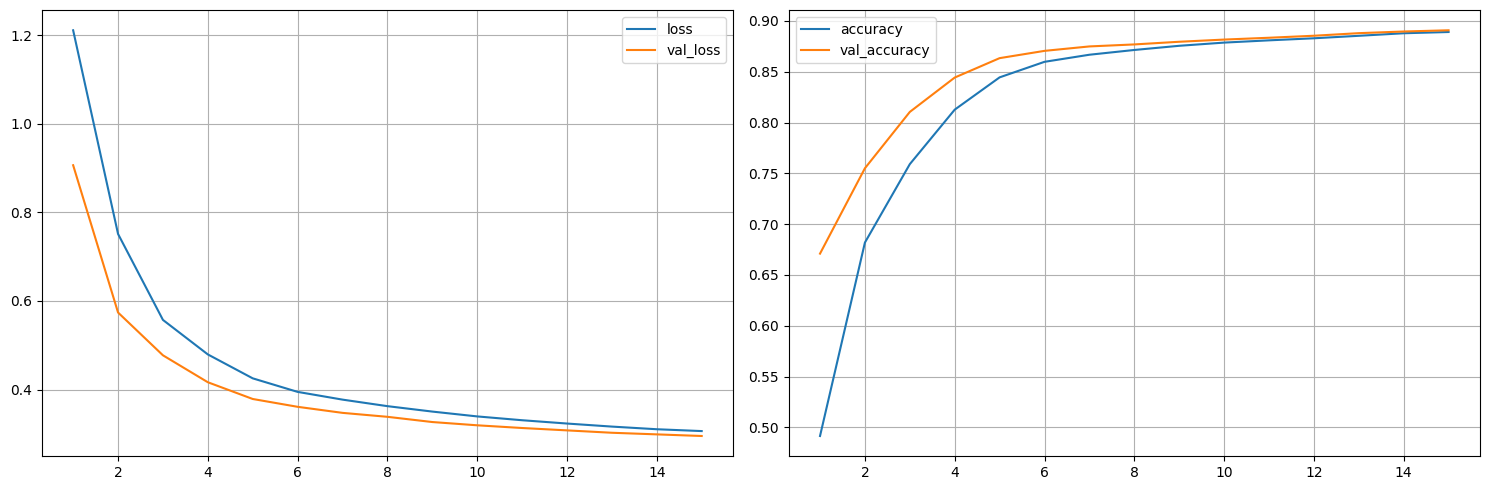

50/50 [==============================] - 2s 39ms/step - loss: 0.3061 - accuracy: 0.8891 - val_loss: 0.2950 - val_accuracy: 0.8908


Resultados finales del KFold:

Lista con los training accuracy finales de cada split:
[0.888990044593811, 0.8903091549873352, 0.8878481388092041, 0.887886643409729, 0.8890647888183594]

Lista con los training loss finales de cada split:
[0.30510443449020386, 0.30150243639945984, 0.30516764521598816, 0.30731356143951416, 0.30613043904304504]

Lista con los validation accuracy finales de cada split:
[0.8920233845710754, 0.8934250473976135, 0.8890348076820374, 0.8908141851425171, 0.8907577991485596]

Lista con los validation loss finales de cada split:
[0.2877267301082611, 0.28552839159965515, 0.29278701543807983, 0.2907320559024811, 0.29503577947616577]

Media de train_accuracy de los diferentes splits = 0.88882
Media de train_loss de los diferentes splits  = 0.30504

Media de val_accuracy de los diferentes splits = 0.89121
Media de val_loss de los diferente

In [15]:
## Diccionario que contendrá los pesos, el tiempo de entrenamiento del modelo y las métricas de 
## loss/accuracy medias del KFold
dic_modelo = {}

if (cargar_pesos == True):
    ## Cargamos el diccionario del modelo y semiflujos de esta ejecución (si no existe error...)
    dic_modelo = obtener_pesos_modelo(hashSemiflujos, hashModelo, pathRelativoPesos, 'LSTM')
    ## Cargamos los pesos entrenados al modelo
    model.set_weights(dic_modelo['pesos'])
    ## Cargamos los resultados que se obtuvieron de training/validación y el tiempo que tardó el entrenamiento
    media_train_accuracy = dic_modelo['media_train_accuracy']
    media_train_loss = dic_modelo['media_train_loss']
    media_val_accuracy = dic_modelo['media_val_accuracy']
    media_val_loss = dic_modelo['media_val_loss']
    
    desviacion_train_acurracy = dic_modelo['desviacion_train_acurracy']
    desviacion_train_loss = dic_modelo['desviacion_train_loss']
    desviacion_val_acurracy = dic_modelo['desviacion_val_acurracy']
    desviacion_val_loss = dic_modelo['desviacion_val_loss']
    
    min_entrenamiento = dic_modelo['min_entrenamiento']
    print("\nPesos cargados de un entrenamiento anterior!")

else:
    ## Vamos a entrenar el modelo
    start_time = time.time()
    
    media_train_accuracy,media_train_loss,media_val_accuracy,media_val_loss,desviacion_train_acurracy,\
    desviacion_train_loss,desviacion_val_acurracy,desviacion_val_loss,min_entrenamiento = \
    entrenar_LSTM_kfold(lista_KFold,X_train_bruto,y_train_bruto,dic_modelo,pesos_virgenes,model,\
                        num_capas_lstm,input_shape,hidden_state,mlp_units,lstm_dropout,mlp_dropout,\
                        learning_rate,batch_size,epochs,n_classes,rutaResultados,hashSemiflujos,\
                        hashModelo,guardar_resultados)
    
    calcular_tiempo(start_time)

## -------------------------------------------------------------------------------------------------------------------

## Evaluamos el modelo con el set de test 

In [16]:
## Calculamos el loss y accuracy sobre el set de test
loss_test, accuracy_test = model.evaluate(X_test, y_test, batch_size=batch_size, verbose=1)

## Obtenemos las predicciones para poder obtener métricas
y_pred = model.predict(X_test,batch_size=batch_size)


7/7 [==============================] - 0s 13ms/step - loss: 0.2870 - accuracy: 0.8926


2023-06-22 13:11:28.807823: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'gradients/split_2_grad/concat/split_2/split_dim' with dtype int32
	 [[{{node gradients/split_2_grad/concat/split_2/split_dim}}]]
2023-06-22 13:11:28.808664: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You must feed a value for placeholder tensor 'gradients/split_grad/concat/split/split_dim' with dtype int32
	 [[{{node gradients/split_grad/concat/split/split_dim}}]]
2023-06-22 13:11:28.809255: I tensorflow/core/common_runtime/executor.cc:1197] [/device:CPU:0] (DEBUG INFO) Executor start aborting (this does not indicate an error and you can ignore this message): INVALID_ARGUMENT: You mus

7/7 [==============================] - 0s 12ms/step


## -------------------------------------------------------------------------------------------------------------------

## Métricas finales del modelo

Las métricas obtenidas para el modelo son las siguientes:

Accuracy_test = 0.8926

Loss_test = 0.287

Accuracy_training = 0.8888

Loss_training = 0.305

Accuracy_validation = 0.8912

Loss_validation = 0.2904

Desviacion_train_acurracy = 0.0009

Desviacion_train_loss = 0.0019

Desviacion_val_acurracy = 0.0015

Desviacion_val_loss = 0.0034

Cohen kappa score = 0.8363

Matthews correlation coefficient = 0.846

Log loss = 0.287

Roc AUC score = 0.9517


Generic classification report:

               precision    recall  f1-score   support

         Chat       0.00      0.00      0.00       132
        Email       0.00      0.00      0.00        17
File
Transfer       0.81      0.99      0.89     26658
    Streaming       0.96      0.69      0.80     20741
         VoIP       0.98      0.98      0.98     21418

     accuracy                           0.89     68966
    macro avg       0.55      0.53      0.53     68966
 weighted avg       0.90      0.89      0.89     68966



Confusion Matr

/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.8/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


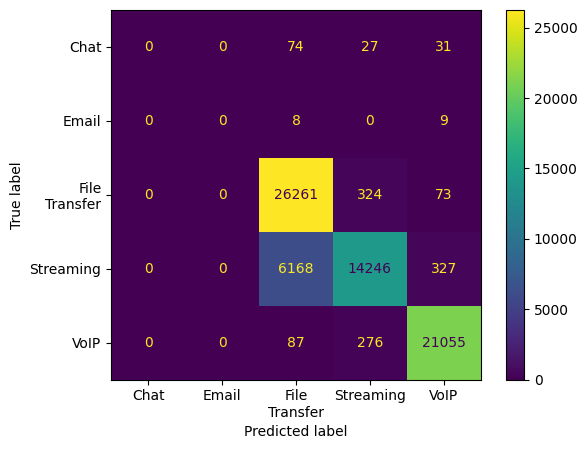

In [17]:
## Obtenemos e imprimimos las métricas
dic_metricas = obtener_metricas_modelo(y_test,y_pred,accuracy_test,loss_test,media_train_accuracy,media_train_loss\
                                       ,media_val_accuracy,media_val_loss,desviacion_train_acurracy,desviacion_train_loss\
                                       ,desviacion_val_acurracy,desviacion_val_loss,hashSemiflujos, hashModelo,\
                                       rutaResultados, guardar_resultados,categorias_semiflujos)


## Obtener características de uso del PC

In [18]:
if (cargar_pesos == False):
    CPU,RAM,picoRAM,nombre_GPU,VRAM,picoVRAM = obtener_especificaciones_pc()
else: 
    ## Obtenemos las características del entrenamiento que ya se hizo
    CPU = dic_modelo['CPU']
    RAM = dic_modelo['RAM']
    picoRAM = dic_modelo['picoRAM']
    nombre_GPU = dic_modelo['nombre_GPU']
    VRAM = dic_modelo['VRAM']
    picoVRAM = dic_modelo['picoVRAM']
    


PID del entrenamiento = 3373

Características del PC donde se ha ejecutado el entrenamiento:
- CPU = AMD Ryzen 7 5700X 8-Core Processor
- RAM = 64GB
- Pico de uso de RAM = 16.3GB
- GPU = NVIDIA GeForce RTX 3090
- VRAM = 24GB
- Pico de uso de VRAM = 3.6GB


## Guardar resultados (o no)

In [19]:
if(guardar_resultados == True):
    ## Añadimos al diccionario de métricas los hiperparámetros utilizados, así como otros datos de interés
    dic_metricas["epochs"] = epochs
    dic_metricas["batch_size"] = batch_size
    dic_metricas["learning_rate"] = learning_rate
    dic_metricas["num_capas_lstm"] = num_capas_lstm
    dic_metricas["hidden_state"] = hidden_state
    dic_metricas["mlp_units"] = mlp_units
    dic_metricas["lstm_dropout"] = lstm_dropout
    dic_metricas["mlp_dropout"] = mlp_dropout  
    dic_metricas["num_folds"] = num_folds
    dic_metricas["normalizacion"] = normalizar
    dic_metricas["min_entrenamiento"] = min_entrenamiento 
    dic_metricas["hashSemiflujos"] = hashSemiflujos
    dic_metricas["hashModelo"] = hashModelo
    dic_metricas["timestamp"] = get_timestamp()
    dic_metricas["CPU"] = CPU
    dic_metricas["RAM"] = RAM
    dic_metricas["pico_uso_RAM"] = picoRAM
    dic_metricas["GPU"] = nombre_GPU
    dic_metricas["VRAM"] = VRAM
    dic_metricas["pico_uso_VRAM"] = picoVRAM
    ## Guardamos el diccionario de métricas en el CSV de métricas y resultados
    guardar_resultados_modelo(dic_metricas, rutaResultados,hashModelo,cargar_pesos,'LSTM')
    print("Se han guardado los resultados")
else:
    print("\nNo se han guardado los resultados")

Se han guardado los resultados


## -------------------------------------------------------------------------------------------------------------------

## Último paso, guardar (o no) los pesos del modelo

In [20]:
## Si la opción está habilitada, se guarda el diccionario con los pesos y tiempo de ejecución del modelo

if (guardar_pesos == True):
    dic_modelo['pesos'] = model.get_weights()
    dic_modelo['media_train_accuracy'] = media_train_accuracy
    dic_modelo['media_train_loss'] = media_train_loss
    dic_modelo['media_val_accuracy'] = media_val_accuracy
    dic_modelo['media_val_loss'] = media_val_loss
        
    dic_modelo['desviacion_train_acurracy'] = desviacion_train_acurracy
    dic_modelo['desviacion_train_loss'] = desviacion_train_loss
    dic_modelo['desviacion_val_acurracy'] = desviacion_val_acurracy
    dic_modelo['desviacion_val_loss'] = desviacion_val_loss
  
    dic_modelo['CPU'] = CPU
    dic_modelo['RAM'] = RAM
    dic_modelo['picoRAM'] = picoRAM
    dic_modelo['nombre_GPU'] = nombre_GPU
    dic_modelo['VRAM'] = VRAM
    dic_modelo['picoVRAM'] = picoVRAM
    guardar_pesos_modelo(hashSemiflujos,hashModelo, dic_modelo, pathRelativoPesos, 'LSTM')
    print("\nSe han guardado los pesos")
else:
    print("\nNO se han guardado los pesos")



Se han guardado los pesos


## ------------------------------------- 🎉 FIN DEL NOTEBOOK 🎉 -------------------------------------